In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

DATA_ROOT = Path("/content/drive/MyDrive/Research/A. Segmentation")

assert DATA_ROOT.exists(), f"Dataset folder not found: {DATA_ROOT}"

print("Dataset root:", DATA_ROOT)


for p in sorted(DATA_ROOT.rglob("*")):
    if p.is_dir() and (
        "training set" in p.name.lower()
        or "testing set" in p.name.lower()
        or "microaneurysm" in p.name.lower()
        or "haemorrhage" in p.name.lower()
        or "hemorrhage" in p.name.lower()
        or "exudate" in p.name.lower()
    ):
        print(p)


Mounted at /content/drive
Dataset root: /content/drive/MyDrive/Research/A. Segmentation
/content/drive/MyDrive/Research/A. Segmentation/1. Original Images/a. Training Set
/content/drive/MyDrive/Research/A. Segmentation/1. Original Images/b. Testing Set
/content/drive/MyDrive/Research/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set
/content/drive/MyDrive/Research/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/1. Microaneurysms
/content/drive/MyDrive/Research/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/2. Haemorrhages
/content/drive/MyDrive/Research/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/3. Hard Exudates
/content/drive/MyDrive/Research/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/4. Soft Exudates
/content/drive/MyDrive/Research/A. Segmentation/2. All Segmentation Groundtruths/b. Testing Set
/content/drive/MyDrive/Research/A. Segmentation/2. All Segmentation Groundtruths/b. Testing Set/1.

In [2]:
import re
import time
import random
import warnings
from pathlib import Path
from collections import defaultdict

import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    average_precision_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [32]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}

LESIONS = ["MA", "HE", "EX", "SE"]

LESION_KEYWORDS = {
    "MA": ["microaneurysm"],
    "HE": ["haemorrhage", "hemorrhage"],
    "EX": ["hard exudate"],
    "SE": ["soft exudate"]
}

ORIGINAL_DIR = DATA_ROOT / "1. Original Images"

assert ORIGINAL_DIR.exists(), (
    f"Original Images directory not found: {ORIGINAL_DIR}"
)


def get_image_id(path):
    """Extract a canonical ID, ignoring duplicate suffixes."""
    match = re.search(r"IDRiD[_-]?(\d+)", path.name, re.IGNORECASE)

    if match:
        return f"IDRiD_{int(match.group(1)):02d}"

    return None


def detect_split(path):
    parts = [part.lower() for part in path.parts]

    if any("training set" in part for part in parts):
        return "train"

    if any("testing set" in part for part in parts):
        return "test"

    return None


# Collect original images
images = {"train": {}, "test": {}}

for path in ORIGINAL_DIR.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in IMAGE_EXTS:
        continue

    split = detect_split(path)
    image_id = get_image_id(path)

    if split and image_id:
        images[split].setdefault(image_id, []).append(path)


# Collect lesion masks from the ground-truth directories
masks = {
    split: {lesion: defaultdict(list) for lesion in LESIONS}
    for split in ["train", "test"]
}

for path in DATA_ROOT.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in IMAGE_EXTS:
        continue

    if "original images" in str(path.parent).lower():
        continue

    split = detect_split(path)
    image_id = get_image_id(path)

    if not split or not image_id:
        continue

    full_path = str(path).lower()

    for lesion, keywords in LESION_KEYWORDS.items():
        if any(keyword in full_path for keyword in keywords):
            masks[split][lesion][image_id].append(path)
            break


def choose_file(paths):
    """Prefer the original filename over a '(2)' duplicate."""
    return sorted(
        paths,
        key=lambda p: (
            bool(re.search(r"\(\d+\)", p.stem)),
            len(p.name),
            p.name
        )
    )[0]


records = {"train": [], "test": []}

for split in ["train", "test"]:
    for image_id, image_paths in sorted(images[split].items()):

        record = {
            "id": image_id,
            "image": choose_file(image_paths),
            "masks": {},
            "valid": {}
        }

        for lesion in LESIONS:
            found = masks[split][lesion].get(image_id, [])

            record["masks"][lesion] = (
                choose_file(found) if found else None
            )

            record["valid"][lesion] = bool(found)

        records[split].append(record)


for split in ["train", "test"]:
    print(f"\n{split.upper()} ORIGINAL IMAGES:", len(records[split]))

    for lesion in LESIONS:
        count = sum(
            r["valid"][lesion] for r in records[split]
        )
        print(f"{lesion}: {count} annotated images")

    duplicate_images = sum(
        len(v) > 1 for v in images[split].values()
    )
    print("Duplicate original-image IDs:", duplicate_images)


TRAIN ORIGINAL IMAGES: 54
MA: 54 annotated images
HE: 53 annotated images
EX: 54 annotated images
SE: 26 annotated images
Duplicate original-image IDs: 0

TEST ORIGINAL IMAGES: 27
MA: 27 annotated images
HE: 27 annotated images
EX: 27 annotated images
SE: 14 annotated images
Duplicate original-image IDs: 0


In [33]:
IMG_SIZE = 512

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)


def load_fundus(path):
    image = cv2.imread(str(path))

    if image is None:
        raise ValueError(f"Cannot read image: {path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    image = cv2.resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_AREA
    )

    # Apply CLAHE to green channel
    green = clahe.apply(image[:, :, 1])
    image[:, :, 1] = green

    return image


def load_mask(path):
    mask = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

    if mask is None:
        raise ValueError(f"Cannot read mask: {path}")

    # Convert RGB/RGBA masks to a single channel
    if mask.ndim == 3:
        mask = mask[:, :, :3]
        mask = np.max(mask, axis=2)

    mask = cv2.resize(
        mask,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_NEAREST
    )

    # Assumes the lesion annotation is represented by nonzero pixels
    return (mask > 0).astype(np.float32)


class IDRiDDataset(Dataset):
    def __init__(self, records, augment=False):
        self.records = records
        self.augment = augment

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]

        image = load_fundus(record["image"])

        target = np.zeros(
            (4, IMG_SIZE, IMG_SIZE),
            dtype=np.float32
        )

        valid = np.array(
            [record["valid"][lesion] for lesion in LESIONS],
            dtype=np.float32
        )

        for channel, lesion in enumerate(LESIONS):
            mask_path = record["masks"][lesion]

            if mask_path is not None:
                target[channel] = load_mask(mask_path)

        # Apply identical spatial transforms to image and all masks
        if self.augment:
            if random.random() < 0.5:
                image = np.fliplr(image).copy()
                target = np.flip(target, axis=2).copy()

            if random.random() < 0.5:
                image = np.flipud(image).copy()
                target = np.flip(target, axis=1).copy()

            k = random.randint(0, 3)
            image = np.rot90(image, k).copy()
            target = np.rot90(target, k, axes=(1, 2)).copy()

        image = image.astype(np.float32) / 255.0

        image = torch.from_numpy(
            image.transpose(2, 0, 1).copy()
        )

        target = torch.from_numpy(target)
        valid = torch.from_numpy(valid)

        return image, target, valid, record["id"]

In [34]:
train_records, val_records = train_test_split(
    records["train"],
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)

test_records = records["test"]

print("Training images:", len(train_records))
print("Validation images:", len(val_records))
print("Testing images:", len(test_records))

train_dataset = IDRiDDataset(train_records, augment=True)
val_dataset = IDRiDDataset(val_records, augment=False)
test_dataset = IDRiDDataset(test_records, augment=False)

BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

Training images: 43
Validation images: 11
Testing images: 27


In [35]:
train_records, val_records = train_test_split(
    records["train"],
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)

test_records = records["test"]

print("Training images:", len(train_records))
print("Validation images:", len(val_records))
print("Testing images:", len(test_records))

train_dataset = IDRiDDataset(train_records, augment=True)
val_dataset = IDRiDDataset(val_records, augment=False)
test_dataset = IDRiDDataset(test_records, augment=False)

BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

Training images: 43
Validation images: 11
Testing images: 27


In [36]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class MultiScaleBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        branch_channels = out_channels // 3
        remainder = out_channels - 2 * branch_channels

        self.branch1 = nn.Conv2d(
            in_channels, branch_channels, 3, padding=1
        )

        self.branch2 = nn.Conv2d(
            in_channels, branch_channels, 3,
            padding=2, dilation=2
        )

        self.branch3 = nn.Conv2d(
            in_channels, remainder, 3,
            padding=3, dilation=3
        )

        self.fuse = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        features = torch.cat(
            [
                self.branch1(x),
                self.branch2(x),
                self.branch3(x)
            ],
            dim=1
        )

        return self.fuse(features)


class SpatialAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.attention = nn.Sequential(
            nn.Conv2d(channels, 1, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        weights = self.attention(x)
        return x * weights


class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()

        self.attention = SpatialAttention(skip_channels)

        self.conv = ConvBlock(
            in_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):
        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        skip = self.attention(skip)

        x = torch.cat([x, skip], dim=1)

        return self.conv(x)


class MultiScaleAttentionUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=4, base=16):
        super().__init__()

        self.enc1 = ConvBlock(in_channels, base)
        self.enc2 = ConvBlock(base, base * 2)
        self.enc3 = ConvBlock(base * 2, base * 4)
        self.enc4 = ConvBlock(base * 4, base * 8)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = MultiScaleBlock(
            base * 8, base * 16
        )

        self.dec4 = DecoderBlock(
            base * 16, base * 8, base * 8
        )
        self.dec3 = DecoderBlock(
            base * 8, base * 4, base * 4
        )
        self.dec2 = DecoderBlock(
            base * 4, base * 2, base * 2
        )
        self.dec1 = DecoderBlock(
            base * 2, base, base
        )

        # Four independent lesion probability channels
        self.output = nn.Conv2d(base, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(b, e4)
        d3 = self.dec3(d4, e3)
        d2 = self.dec2(d3, e2)
        d1 = self.dec1(d2, e1)

        # Return logits; sigmoid is applied during loss/inference
        return self.output(d1)


model = MultiScaleAttentionUNet().to(DEVICE)

print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

MultiScaleAttentionUNet(
  (enc1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc3): ConvBlock(
   

In [37]:

import torch
import torch.nn.functional as F

def improved_segmentation_loss(
    logits,
    targets,
    valid,
    smooth=1e-6
):
    targets = targets.float()
    valid = valid.float()

    # Expected logits and targets: [B, 4, H, W]
    # Expected valid: [B, 4] annotation flags
    if valid.ndim == 2:
        valid = valid[:, :, None, None]

    valid = valid.expand_as(targets)

    # BCE only over annotated pixels
    bce_map = F.binary_cross_entropy_with_logits(
        logits, targets, reduction="none"
    )

    bce_per_class = (
        (bce_map * valid).sum(dim=(0, 2, 3))
        / valid.sum(dim=(0, 2, 3)).clamp_min(1)
    )

    probs = torch.sigmoid(logits)

    intersection = (probs * targets * valid).sum(
        dim=(0, 2, 3)
    )

    denominator = (
        (probs * valid).sum(dim=(0, 2, 3))
        + (targets * valid).sum(dim=(0, 2, 3))
    )

    dice_per_class = (
        2 * intersection + smooth
    ) / (denominator + smooth)

    # Equal weight for MA, HE, EX and SE
    class_loss = 0.5 * bce_per_class + (
        1.0 - dice_per_class
    )

    # Ignore classes with no valid annotations in this batch
    class_present = valid.sum(dim=(0, 2, 3)) > 0

    if not class_present.any():
        return logits.sum() * 0.0

    return class_loss[class_present].mean()


In [38]:
LEARNING_RATE = 1e-4
EPOCHS = 80
PATIENCE = 12

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=4,
    min_lr=1e-7
)


SAVE_PATH = "/content/best_dr_multilesion_unet.pth"

best_val_loss = float("inf")
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": []
}

start_time = time.time()

for epoch in range(EPOCHS):
    model.train()
    train_total = 0.0

    for images_batch, masks_batch, valid_batch, _ in tqdm(
        train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}"
    ):
        images_batch = images_batch.to(DEVICE)
        masks_batch = masks_batch.to(DEVICE)
        valid_batch = valid_batch.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images_batch)

        loss = improved_segmentation_loss(
            logits, masks_batch, valid_batch
        )

        loss.backward()
        optimizer.step()

        train_total += loss.item()

    train_loss = train_total / max(len(train_loader), 1)

    model.eval()
    val_total = 0.0

    with torch.no_grad():
        for images_batch, masks_batch, valid_batch, _ in val_loader:
            images_batch = images_batch.to(DEVICE)
            masks_batch = masks_batch.to(DEVICE)
            valid_batch = valid_batch.to(DEVICE)

            logits = model(images_batch)

            loss = improved_segmentation_loss(
                logits, masks_batch, valid_batch
            )

            val_total += loss.item()

    val_loss = val_total / max(len(val_loader), 1)

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f} | "
        f"LR: {optimizer.param_groups[0]['lr']:.2e}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(model.state_dict(), SAVE_PATH)
        print("Best model saved.")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

training_seconds = time.time() - start_time

print(f"\nTraining time: {training_seconds / 60:.2f} minutes")
print("Best validation loss:", best_val_loss)

Epoch 1/80:   0%|          | 0/22 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 1.3001 | Validation Loss: 1.3588 | LR: 1.00e-04
Best model saved.


Epoch 2/80:   0%|          | 0/22 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 1.2827 | Validation Loss: 1.3133 | LR: 1.00e-04
Best model saved.


Epoch 3/80:   0%|          | 0/22 [00:00<?, ?it/s]

...

Epoch 78 | Train Loss: 1.0491 | Validation Loss: 1.0610 | LR: 1.00e-04


Epoch 79/80:   0%|          | 0/22 [00:00<?, ?it/s]

Epoch 79 | Train Loss: 1.0453 | Validation Loss: 1.0534 | LR: 1.00e-04
Best model saved.


Epoch 80/80:   0%|          | 0/22 [00:00<?, ?it/s]

Epoch 80 | Train Loss: 1.0437 | Validation Loss: 1.0525 | LR: 1.00e-04
Best model saved.

Training time: 25.77 minutes
Best validation loss: 1.0525176922480266


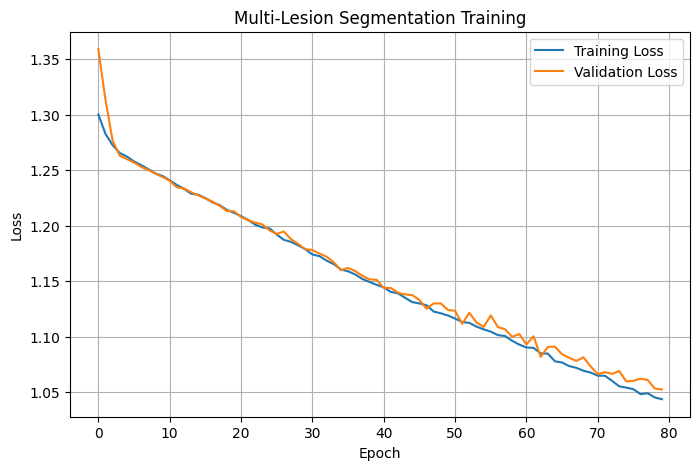

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Multi-Lesion Segmentation Training")
plt.legend()
plt.grid(True)
plt.show()

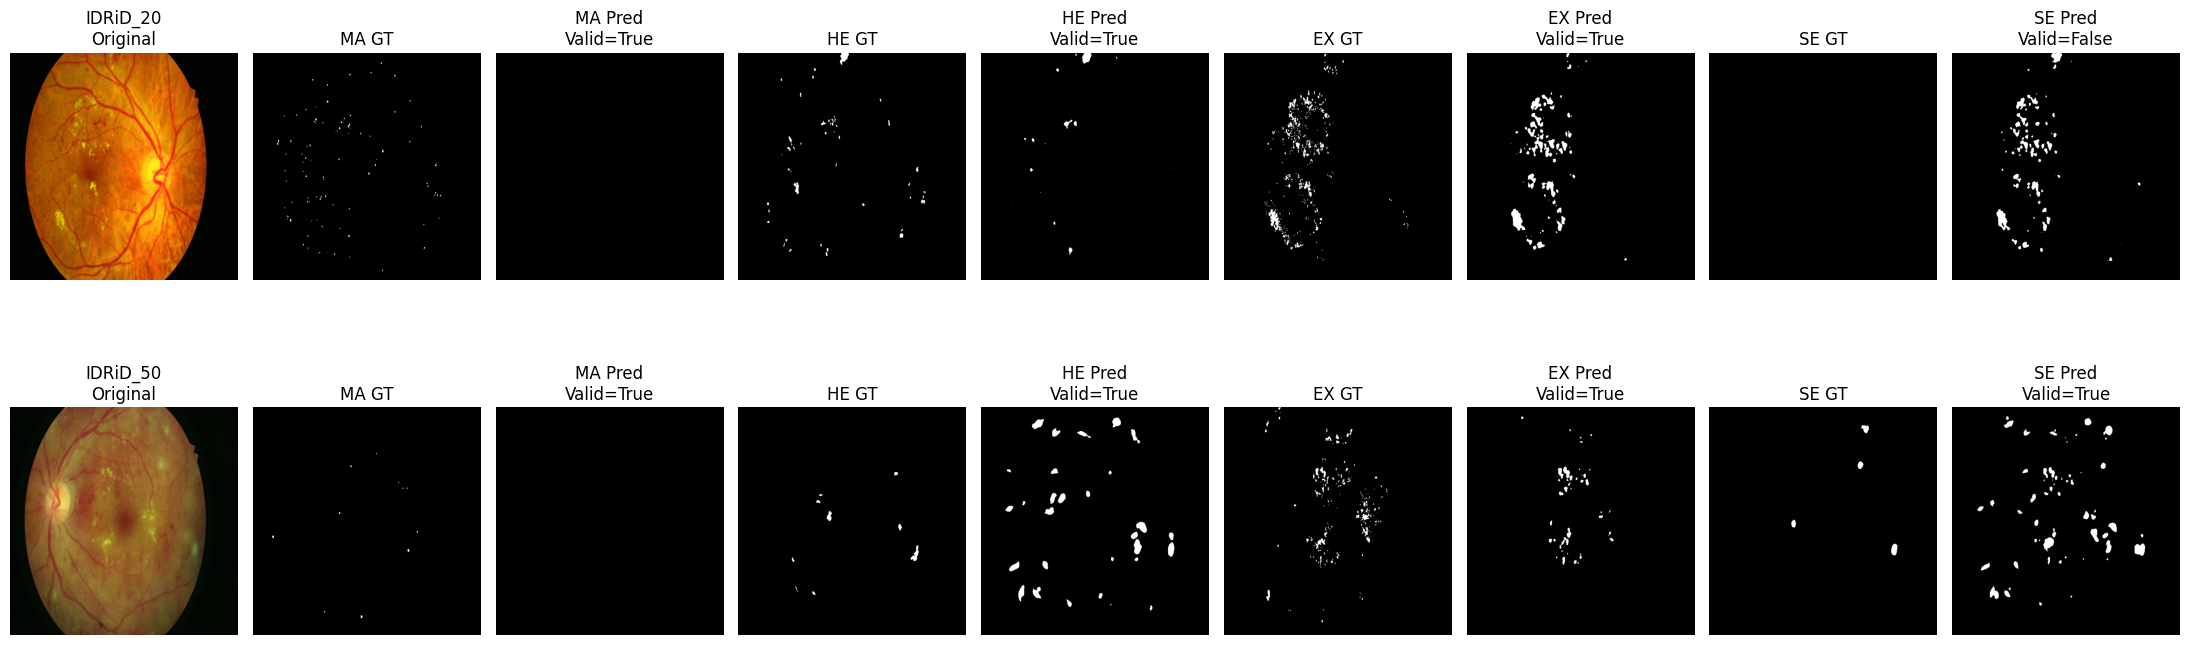

In [41]:
import matplotlib.pyplot as plt
import numpy as np
import torch

LESIONS = ["MA", "HE", "EX", "SE"]
THRESHOLD = 0.5

model.eval()

images, targets, valid, image_ids = next(iter(val_loader))

with torch.no_grad():
    logits = model(images.to(DEVICE))
    probabilities = torch.sigmoid(logits).cpu().numpy()

images = images.cpu().numpy()
targets = targets.cpu().numpy()
valid = valid.cpu().numpy()

n = min(4, len(image_ids))
fig, axes = plt.subplots(n, 9, figsize=(22, 4 * n))

if n == 1:
    axes = np.expand_dims(axes, axis=0)

for b in range(n):
    # Convert normalized image approximately back to display range
    img = np.transpose(images[b], (1, 2, 0))
    img = np.clip(img, 0, 1)

    axes[b, 0].imshow(img)
    axes[b, 0].set_title(f"{image_ids[b]}\nOriginal")
    axes[b, 0].axis("off")

    for i, lesion in enumerate(LESIONS):
        gt = targets[b, i]
        pred = probabilities[b, i] >= THRESHOLD

        axes[b, 1 + 2*i].imshow(gt, cmap="gray")
        axes[b, 1 + 2*i].set_title(f"{lesion} GT")
        axes[b, 1 + 2*i].axis("off")

        axes[b, 2 + 2*i].imshow(pred, cmap="gray")
        axes[b, 2 + 2*i].set_title(
            f"{lesion} Pred\nValid={bool(valid[b, i])}"
        )
        axes[b, 2 + 2*i].axis("off")

plt.tight_layout()
plt.show()

In [42]:
model.eval()

images, masks, valid, _ = next(iter(val_loader))

images = images.to(DEVICE)

with torch.no_grad():
    logits = model(images)

print("Images shape:", images.shape)
print("Logits shape:", logits.shape)
print("Masks shape:", masks.shape)
print("Valid shape:", valid.shape)

Images shape: torch.Size([2, 3, 512, 512])
Logits shape: torch.Size([2, 4, 512, 512])
Masks shape: torch.Size([2, 4, 512, 512])
Valid shape: torch.Size([2, 4])


In [43]:

images, masks, valid, _ = next(iter(val_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Valid:", valid.shape)
print("Valid dimensions:", valid.ndim)
print("Valid dtype:", valid.dtype)


Images: torch.Size([2, 3, 512, 512])
Masks: torch.Size([2, 4, 512, 512])
Valid: torch.Size([2, 4])
Valid dimensions: 2
Valid dtype: torch.float32


In [44]:
print("Logits shape:", logits.shape)
print("Masks shape:", masks.shape)
print("Valid shape:", valid.shape)
print("Valid dimensions:", valid.ndim)

Logits shape: torch.Size([2, 4, 512, 512])
Masks shape: torch.Size([2, 4, 512, 512])
Valid shape: torch.Size([2, 4])
Valid dimensions: 2


In [45]:

images, masks, valid, _ = next(iter(val_loader))

print("Valid shape:", valid.shape)
print("Valid values:")
print(valid)

print("Unique valid values:", torch.unique(valid))


Valid shape: torch.Size([2, 4])
Valid values:
tensor([[1., 1., 1., 0.],
        [1., 1., 1., 1.]])
Unique valid values: tensor([0., 1.])


In [46]:

import torch

model.eval()

class_names = ["MA", "HE", "EX", "SE"]

intersection = torch.zeros(4)
predicted_pixels = torch.zeros(4)
ground_truth_pixels = torch.zeros(4)

with torch.no_grad():
    for images, masks, valid, _ in val_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).float()
        valid = valid.to(DEVICE)

        logits = model(images)
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).float()

        # valid must be [B, 4]: one annotation flag
        # per image and lesion class.
        if valid.ndim != 2 or valid.shape[1] != 4:
            raise ValueError(
                f"Expected valid [B, 4], got {valid.shape}"
            )

        valid = valid.bool()

        for c in range(4):
            # Evaluate only images annotated for this class
            selected = valid[:, c]

            if not selected.any():
                continue

            p = preds[selected, c]
            y = masks[selected, c]

            intersection[c] += (p * y).sum().cpu()
            predicted_pixels[c] += p.sum().cpu()
            ground_truth_pixels[c] += y.sum().cpu()

for c, name in enumerate(class_names):
    dice = (
        2 * intersection[c] /
        (predicted_pixels[c] + ground_truth_pixels[c]).clamp_min(1)
    )

    print(
        f"{name}: Dice={dice.item():.4f}, "
        f"Predicted pixels={predicted_pixels[c].item():.0f}, "
        f"Ground-truth pixels={ground_truth_pixels[c].item():.0f}"
    )


MA: Dice=0.0000, Predicted pixels=0, Ground-truth pixels=4481
HE: Dice=0.2967, Predicted pixels=66489, Ground-truth pixels=21270
EX: Dice=0.5713, Predicted pixels=33520, Ground-truth pixels=25667
SE: Dice=0.0967, Predicted pixels=45019, Ground-truth pixels=4664


In [47]:

import torch

model.eval()
class_names = ["MA", "HE", "EX", "SE"]

prob_sum = torch.zeros(4)
prob_max = torch.zeros(4)
pixel_count = torch.zeros(4)

with torch.no_grad():
    for images, masks, valid, _ in val_loader:
        images = images.to(DEVICE)
        logits = model(images)
        probs = torch.sigmoid(logits).cpu()

        # valid is assumed to be [B, 4] annotation flags
        valid = valid.cpu().bool()

        for c in range(4):
            selected = valid[:, c]

            if selected.any():
                p = probs[selected, c]

                prob_sum[c] += p.sum()
                prob_max[c] = max(prob_max[c], p.max())
                pixel_count[c] += p.numel()

for c, name in enumerate(class_names):
    avg = prob_sum[c] / pixel_count[c].clamp_min(1)

    print(
        f"{name}: "
        f"Average probability={avg.item():.6f}, "
        f"Maximum probability={prob_max[c].item():.6f}"
    )


MA: Average probability=0.128616, Maximum probability=0.483640
HE: Average probability=0.140278, Maximum probability=0.945324
EX: Average probability=0.145800, Maximum probability=0.954039
SE: Average probability=0.206880, Maximum probability=0.865898


In [48]:

import torch

model.eval()
class_names = ["MA", "HE", "EX", "SE"]
thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]

with torch.no_grad():
    images, masks, valid, _ = next(iter(val_loader))

    images = images.to(DEVICE)
    probs = torch.sigmoid(model(images)).cpu()
    masks = masks.cpu()
    valid = valid.bool()

    for c, name in enumerate(class_names):
        selected = valid[:, c]

        if not selected.any():
            print(f"{name}: no annotated images in this batch")
            continue

        p = probs[selected, c]
        y = masks[selected, c] > 0.5

        print(f"\n{name}")

        for threshold in thresholds:
            pred = p >= threshold

            intersection = (pred & y).sum().item()
            pred_count = pred.sum().item()
            gt_count = y.sum().item()

            dice = (
                2 * intersection / (pred_count + gt_count)
                if pred_count + gt_count > 0 else 1.0
            )

            print(
                f"Threshold={threshold:.2f} | "
                f"Predicted pixels={pred_count} | "
                f"Dice={dice:.4f}"
            )



MA
Threshold=0.10 | Predicted pixels=469339 | Dice=0.0024
Threshold=0.20 | Predicted pixels=10930 | Dice=0.0109
Threshold=0.30 | Predicted pixels=5246 | Dice=0.0115
Threshold=0.40 | Predicted pixels=2348 | Dice=0.0146
Threshold=0.50 | Predicted pixels=0 | Dice=0.0000

HE
Threshold=0.10 | Predicted pixels=352666 | Dice=0.0121
Threshold=0.20 | Predicted pixels=27064 | Dice=0.0788
Threshold=0.30 | Predicted pixels=12156 | Dice=0.1202
Threshold=0.40 | Predicted pixels=8361 | Dice=0.1378
Threshold=0.50 | Predicted pixels=6358 | Dice=0.1517

EX
Threshold=0.10 | Predicted pixels=488680 | Dice=0.0264
Threshold=0.20 | Predicted pixels=82005 | Dice=0.1337
Threshold=0.30 | Predicted pixels=14331 | Dice=0.4591
Threshold=0.40 | Predicted pixels=10001 | Dice=0.5205
Threshold=0.50 | Predicted pixels=7662 | Dice=0.5403

SE
Threshold=0.10 | Predicted pixels=262144 | Dice=0.0061
Threshold=0.20 | Predicted pixels=47080 | Dice=0.0331
Threshold=0.30 | Predicted pixels=13875 | Dice=0.1035
Threshold=0.40 | 